In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
hd = pd.read_excel("heart_disease.xlsx", sheet_name = 'Heart_disease')
hd

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,num
0,63,Male,typical angina,145,233,True,lv hypertrophy,150,False,2.3,downsloping,fixed defect,0
1,41,Male,atypical angina,135,203,False,normal,132,False,0.0,flat,fixed defect,0
2,57,Male,asymptomatic,140,192,False,normal,148,False,0.4,flat,fixed defect,0
3,52,Male,typical angina,118,186,False,lv hypertrophy,190,False,0.0,flat,fixed defect,0
4,57,Male,asymptomatic,110,201,False,normal,126,True,1.5,flat,fixed defect,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
903,53,Male,asymptomatic,125,0,FALSE,normal,120,False,1.5,upsloping,reversable defect,4
904,62,Male,asymptomatic,166,170,False,st-t abnormality,120,True,3.0,flat,reversable defect,4
905,56,Male,non-anginal,170,0,False,lv hypertrophy,123,True,2.5,downsloping,normal,4
906,56,Male,non-anginal,144,208,True,st-t abnormality,105,TURE,NaN,downsloping,fixed defect,4


In [3]:
hd.info()

<class 'pandas.DataFrame'>
RangeIndex: 908 entries, 0 to 907
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       908 non-null    int64  
 1   sex       908 non-null    str    
 2   cp        908 non-null    str    
 3   trestbps  908 non-null    int64  
 4   chol      908 non-null    int64  
 5   fbs       908 non-null    object 
 6   restecg   908 non-null    str    
 7   thalch    908 non-null    int64  
 8   exang     908 non-null    object 
 9   oldpeak   846 non-null    float64
 10  slope     908 non-null    str    
 11  thal      908 non-null    str    
 12  num       908 non-null    int64  
dtypes: float64(1), int64(5), object(2), str(5)
memory usage: 132.0+ KB


In [4]:
hd.isnull().sum()

age          0
sex          0
cp           0
trestbps     0
chol         0
fbs          0
restecg      0
thalch       0
exang        0
oldpeak     62
slope        0
thal         0
num          0
dtype: int64

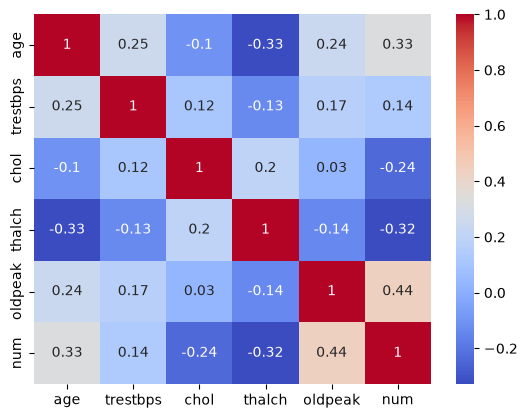

In [5]:
sns.heatmap(hd.corr(numeric_only=True),annot = True, cmap='coolwarm')
plt.show()

As we can see oldpeak feature is more correlated to the num feature

<Axes: xlabel='oldpeak', ylabel='Count'>

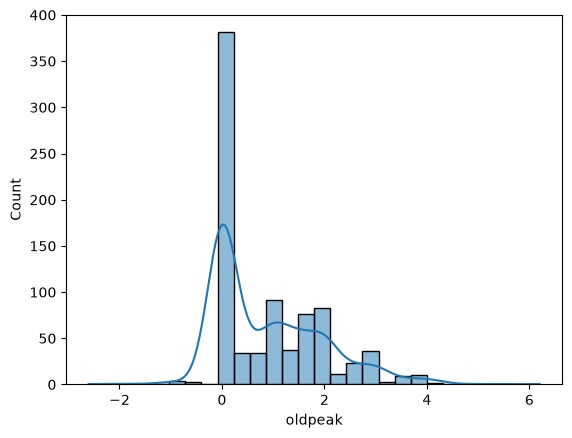

In [6]:
sns.histplot(hd['oldpeak'],kde = True)

oldpeak feature is right skewed so we have to replace the missing values to the median values

In [7]:
hd['oldpeak']=hd['oldpeak'].fillna(hd['oldpeak'].median())

In [8]:
hd.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
slope       0
thal        0
num         0
dtype: int64

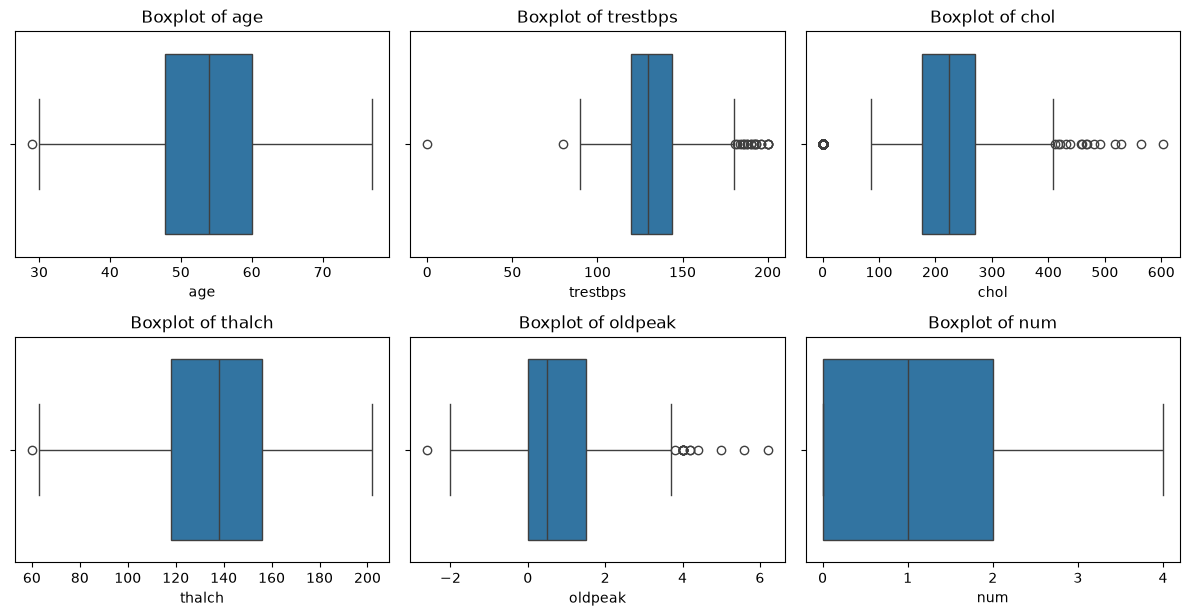

In [9]:

numeric_col = hd.select_dtypes(include=['number']).columns

plt.figure(figsize=(12,15))
for i, col in enumerate(numeric_col, 1):
    plt.subplot(5,3,i)
    sns.boxplot(x = hd[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()



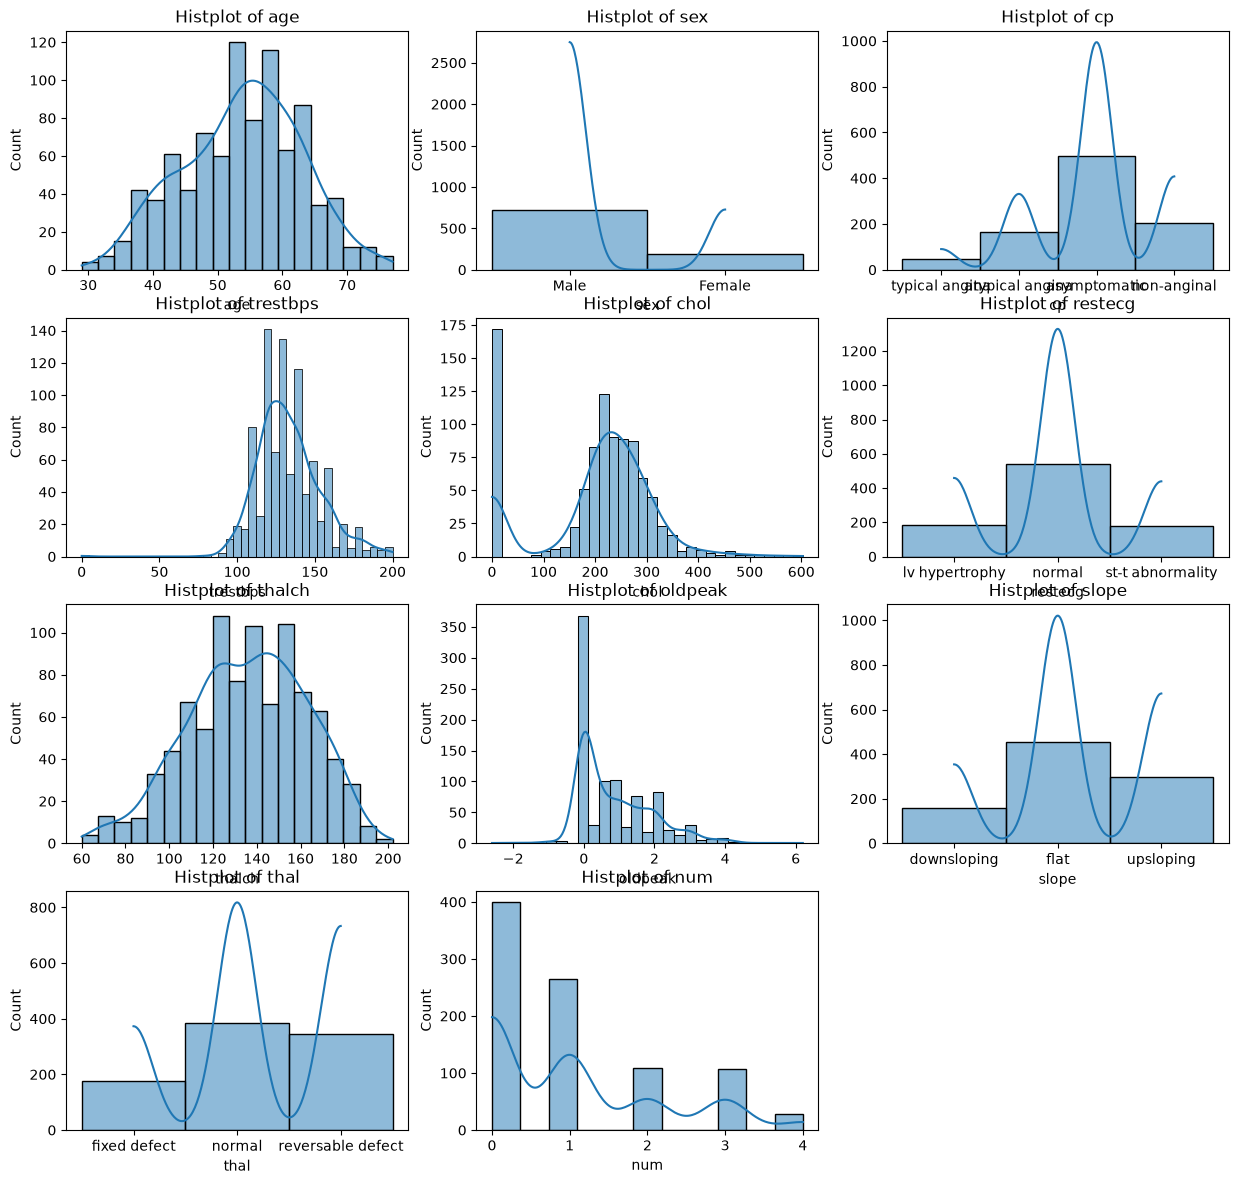

In [10]:

plt.figure(figsize = (15,18))
numeric_cols = hd.select_dtypes(include=['number','string']).columns
for i ,col in enumerate(numeric_cols,1):
    plt.subplot(5,3,i)
    sns.histplot(hd[col],kde = True)
    plt.title(f"Histplot of {col}")

plt.show()

    need to replace outliers from numerical columns 
    no need to replace outliers from categorical column beacause its actual string values 

In [11]:
for col in numeric_col:
    q1 =hd[col].quantile(0.25)
    q3 =hd[col].quantile(0.75)

    iqr = q3 - q1
    lower = q1 - 1.5*iqr
    upper = q3 + 1.5*iqr

    outliers = hd[(hd[col]<lower) | (hd[col]>upper)][col]
    print(f"{col}:{len(outliers)} outliears found")
    hd[col] = hd[col].clip(lower = lower, upper = upper)

age:1 outliears found
trestbps:22 outliears found
chol:187 outliears found
thalch:1 outliears found
oldpeak:16 outliears found
num:0 outliears found


<Axes: xlabel='oldpeak'>

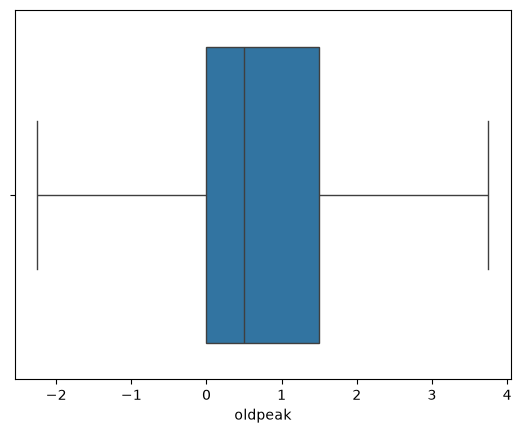

In [12]:
sns.boxplot(x = hd['oldpeak'])

outliers removes successfully

In [13]:
hd.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,num
0,63.0,Male,typical angina,145,233.0,True,lv hypertrophy,150,False,2.3,downsloping,fixed defect,0
1,41.0,Male,atypical angina,135,203.0,False,normal,132,False,0.0,flat,fixed defect,0
2,57.0,Male,asymptomatic,140,192.0,False,normal,148,False,0.4,flat,fixed defect,0
3,52.0,Male,typical angina,118,186.0,False,lv hypertrophy,190,False,0.0,flat,fixed defect,0
4,57.0,Male,asymptomatic,110,201.0,False,normal,126,True,1.5,flat,fixed defect,0


# Feature Engineering

In [14]:
# Using Map Function Put value for Male=1, Female = 0  
hd['sex'] = hd['sex'].map({'Male' : 1, 'Female':0})

In [15]:
hd['fbs'].unique() # there is only two object 'True' and 'False' but some object is on Uppercase
#transform all object into lower case 
#same method uses for "exang" feature

array([True, False, 'FALSE', 'TRUE'], dtype=object)

In [16]:
hd['exang'].unique() 

array([False, True, 'FALSE', 'TURE'], dtype=object)

In [ ]:
hd['exang'].value_counts()

In [17]:
#there is the spelling mistake "Ture" we have to replace it with "true" otherwise it'll creted null values
hd['fbs'] = hd['fbs'].astype(str).str.lower()
hd['exang'] = hd['exang'].astype(str).str.lower()

In [19]:
#Also for fbs(Fasting Blood sugar True = 1, False = 0)
hd['fbs'] = hd['fbs'].map({'true': 1, 'false':0})
hd['exang'] = hd['exang'].map({'true': 1, 'ture':1, 'false':0})

In [20]:
hd

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,num
0,63.0,1,typical angina,145,233.000,1,lv hypertrophy,150,0,2.3,downsloping,fixed defect,0
1,41.0,1,atypical angina,135,203.000,0,normal,132,0,0.0,flat,fixed defect,0
2,57.0,1,asymptomatic,140,192.000,0,normal,148,0,0.4,flat,fixed defect,0
3,52.0,1,typical angina,118,186.000,0,lv hypertrophy,190,0,0.0,flat,fixed defect,0
4,57.0,1,asymptomatic,110,201.000,0,normal,126,1,1.5,flat,fixed defect,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
903,53.0,1,asymptomatic,125,36.875,0,normal,120,0,1.5,upsloping,reversable defect,4
904,62.0,1,asymptomatic,166,170.000,0,st-t abnormality,120,1,3.0,flat,reversable defect,4
905,56.0,1,non-anginal,170,36.875,0,lv hypertrophy,123,1,2.5,downsloping,normal,4
906,56.0,1,non-anginal,144,208.000,1,st-t abnormality,105,1,0.5,downsloping,fixed defect,4


In [27]:
hd['thal'].unique()

<ArrowStringArray>
['fixed defect', 'normal', 'reversable defect']
Length: 3, dtype: str

In [28]:
#One Hot Encoding 
categorical_col= ['cp','restecg','slope','thal']

hd = pd.get_dummies(hd, columns = categorical_col, drop_first = True)

print(hd.shape)
hd.head()

(908, 18)


,age,sex,trestbps,chol,fbs,thalch,exang,oldpeak,num,cp_atypical angina,cp_non-anginal,cp_typical angina,restecg_normal,restecg_st-t abnormality,slope_flat,slope_upsloping,thal_normal,thal_reversable defect
0,63.0,1,145,233.0,1,150,0,2.3,0,False,False,True,False,False,False,False,False,False
1,41.0,1,135,203.0,0,132,0,0.0,0,True,False,False,True,False,True,False,False,False
2,57.0,1,140,192.0,0,148,0,0.4,0,False,False,False,True,False,True,False,False,False
3,52.0,1,118,186.0,0,190,0,0.0,0,False,False,True,False,False,True,False,False,False
4,57.0,1,110,201.0,0,126,1,1.5,0,False,False,False,True,False,True,False,False,False


In [29]:
#successfully convert 'bool' dtype into 'int' 
hd = hd.astype({col:int for col in hd.select_dtypes(include = ['bool']).columns})

# Train Test Split

In [40]:
X = hd.drop(columns='num')
y = hd['num']

In [42]:
from sklearn.model_selection import train_test_split

In [43]:
X_train, X_test, y_train,y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

# Training the model 

In [49]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

dt_model = DecisionTreeClassifier(random_state=42)

#train the data
dt_model.fit(X_train,y_train)

y_pred = dt_model.predict(X_test)

In [52]:
#evaluation

accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred,average = 'weighted', zero_division=0)
recall = recall_score(y_test,y_pred, average = 'weighted',zero_division = 0)
f1 = f1_score(y_test,y_pred, average = 'weighted', zero_division=0)

print(f"Accuracy Score {accuracy:.4f}")
print(f"Precision Score {precision:.4f}")
print(f"Recall Score {recall:.4f}")
print(f"f1_score {f1:.4f}")

# performance is weak as we can see 

Accuracy Score 0.5000
Precision Score 0.4925
Recall Score 0.5000
f1_score 0.4954


# Hyperparameter Tuning

In [65]:
from sklearn.model_selection import GridSearchCV

#Define the prameter grid to search over

param_grid = {
    'criterion':['gini','entropy','log_loss'],
    'max_depth':[3, 5, 7, 10, 15, None],
    'min_samples_split':[2, 5, 10, 20],
    'min_samples_leaf':[1, 2, 5, 10]
}

#initialize the Decision Tree Classifier
dt = DecisionTreeClassifier(random_state = 42)

#set up gridsearch cv with 5-fold cross validation

grid_search = GridSearchCV(
    estimator = dt,
    param_grid = param_grid,
    cv = 5,
    n_jobs = -1
)

grid_search.fit(X_train, y_train)

print("Best Hyperparameter model found:")
print(grid_search.best_params_)
print(f"\nBest Cross Validation Accuracy:{grid_search.best_score_:.4f}")

best_model =  grid_search.best_estimator_
y_pred_tune = best_model.predict(X_test)

tune_accuracy = accuracy_score(y_test, y_pred_tune)
print(f"Test Set accuracy with tuneed model : {tune_accuracy}")

Best Hyperparameter model found:
{'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 5, 'min_samples_split': 2}

Best Cross Validation Accuracy:0.5537
Test Set accuracy with tuneed model : 0.5439560439560439


In [66]:
accuracy_t = accuracy_score(y_test,y_pred_tune)
precision_t = precision_score(y_test,y_pred_tune,average = 'weighted', zero_division=0)
recall_t = recall_score(y_test,y_pred_tune, average = 'weighted',zero_division = 0)
f1_t = f1_score(y_test,y_pred_tune, average = 'weighted', zero_division=0)

print(f"Accuracy Score {accuracy_t:.4f}")
print(f"Precision Score {precision_t:.4f}")
print(f"Recall Score {recall_t:.4f}")
print(f"f1_score {f1_t:.4f}")

Accuracy Score 0.5440
Precision Score 0.4624
Recall Score 0.5440
f1_score 0.4996


In [62]:
print(hd['num'].value_counts())

num
0    399
1    265
2    109
3    107
4     28
Name: count, dtype: int64


In [67]:
from sklearn.ensemble import RandomForestClassifier

# Initialize and train a Random Forest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Evaluate
y_pred_rf = rf_model.predict(X_test)
print(f"Random Forest Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")

Random Forest Accuracy: 0.5934


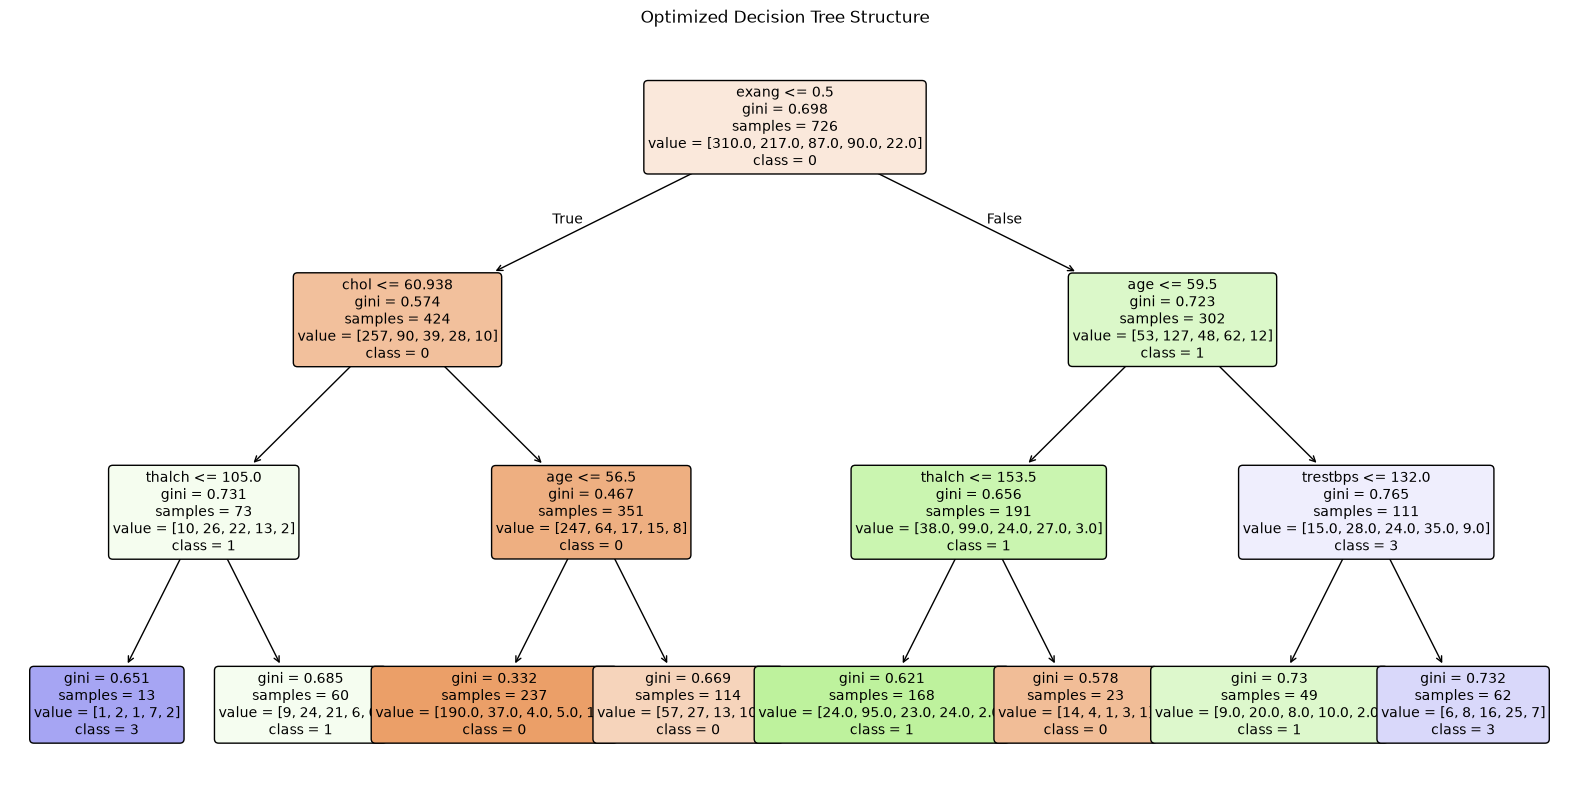

In [68]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

# Plot the best tree found by GridSearchCV
plot_tree(
    best_model, 
    feature_names=X.columns, 
    class_names=[str(c) for c in sorted(y.unique())], 
    filled=True, 
    rounded=True,
    fontsize=10
)

plt.title("Optimized Decision Tree Structure")
plt.show()

Top Features Driving the Model:
              Feature  Importance
6               exang    0.432233
3                chol    0.253914
0                 age    0.165503
5              thalch    0.111412
2            trestbps    0.036938
4                 fbs    0.000000
1                 sex    0.000000
7             oldpeak    0.000000
8  cp_atypical angina    0.000000
9      cp_non-anginal    0.000000


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_13236\1106596021.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importances.head(10), palette='viridis')


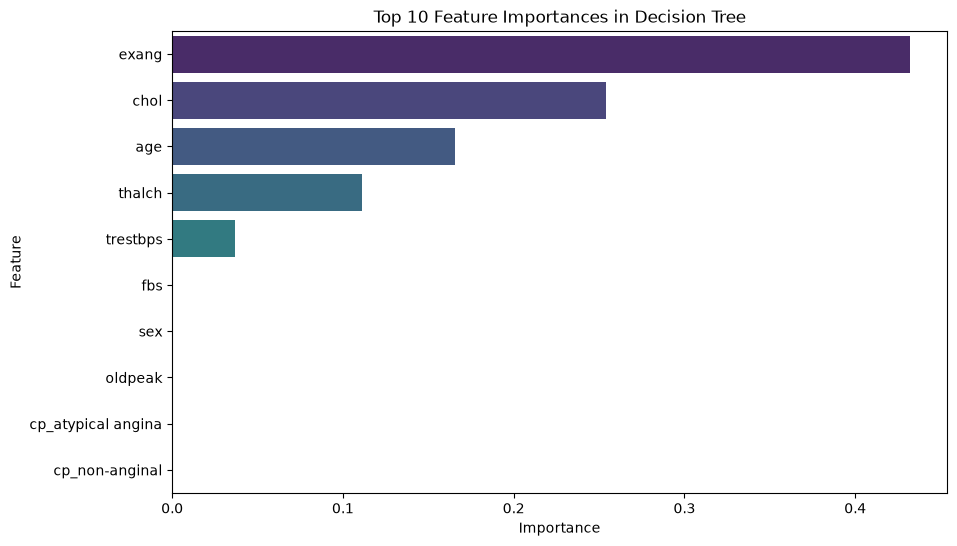

In [69]:
# Create a DataFrame for feature importances
feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("Top Features Driving the Model:")
print(feature_importances.head(10))

# Optional: Plot them
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importances.head(10), palette='viridis')
plt.title("Top 10 Feature Importances in Decision Tree")
plt.show()

### What is the difference between the Label encoding and One-hot encoding?

       Label Encoding:-Assigns each unique category a unique integer value (e.g., Normal = 0, Fixed Defect = 1, Reversible Defect = 2).It introduces an implied mathematical order (ranking) between categories. For example, the model might interpret 2 as "greater than" 0. For unordered categorical features (like chest pain types or defect types), this can confuse models like Decision Trees or Linear Models by making them think category 2 is mathematically "higher" or more important than category 0.

       One-Hot Encoding:- Creates seperate columns fot each object , increases the number of feature in dataset
       It treats every category independently with no false hierarchy or ranking, making it much safer for most machine learning algorithms when dealing with nominal (unordered) categorical data.

### What are some common hyperparameters of decision tree models, and how do they affect the model's performance?

 
	  The mathematical function used to measure the quality of a split. Common options are Gini impurity (measures the probability of a mislabeled element) and entropy (measures information gain/uncertainty).
	 Performance impact: Changes how the algorithm evaluates feature splits. Gini is usually faster to compute, while entropy can sometimes produce slightly more balanced trees.
 
max_depth
        
    What it controls: The maximum number of levels the tree is allowed to grow.
    Performance impact:A high or None value allows the tree to capture complex patterns, which often leads to overfitting (low training error, high test error) A low value restricts complexity, which often leads to underfitting (high bias, poor accuracy on both training and test data).

min_samples_split
           
           What it controls: The minimum number of samples required to split an internal node. Can be set as an absolute integer or a fraction.
           Performance impact:Small values allow the tree to split on very small subsets of data, increasing overfitting risk.Large values force the tree to make broader generalizations, reducing complexity and increasing bias.

min_samples_leaf
	
         
     What it controls: The minimum number of samples required to be at a terminal leaf node.Performance impact:A value of 1 allows leaves to isolate single data points, heightening overfitting.Higher values smooth out predictions by ensuring each leaf represents a meaningful cohort of data points.

max_features
	 
    
     What it controls: The number or proportion of features to consider when looking for the best split (options include None, integer, float, sqrt, or log2).Performance impact: Limiting features forces the tree to evaluate alternative predictors, reducing correlation between trees (essential when building ensemble models like Random Forests) and lowering variance.



min_impurity_decrease
    
        What it controls: A threshold dictating that a node will only split if the impurity decreases by at least that amount.
     Performance impact: Acts as an early-stopping mechanism for splits; higher values result in smaller, more conservative trees